In [34]:
#!/usr/bin/env python
# coding: utf-8
"""
Generate ICs for GENGA with a piecewise disk:
- Sigma(1 AU) = 8 g/cm^2
- Outer (0.7–2 AU): Sigma ∝ a^(-3/2)
- Inner taper (0.3–0.7 AU): linear ramp from 0 at 0.3 to Sigma(0.7 AU) at 0.7


We sample semi-major axes from p(a) ∝ a * Sigma(a) (annulus area factor!).
This replaces previous samplers that did not include the area factor or the
piecewise taper correctly.


Output format (for param.dat):
Input file Format: << m a e inc O w M >>
Angle units: radian


Notes:
- Masses written in solar masses.
- a in AU, angles in radians.
- Do NOT include the star in this file; set it in param.dat.
"""


import numpy as np
import matplotlib
%matplotlib inline  
# matplotlib.use("TkAgg")    # or "Qt5Agg" depending on what you have installed
import matplotlib.pyplot as plt
from astropy import units as u
from scipy.stats import norm

In [ ]:
#!/usr/bin/env python
# coding: utf-8
"""
Generate ICs for GENGA with a piecewise disk:
- Sigma(1 AU) = 8 g/cm^2
- Outer (0.7–2 AU): Sigma ∝ a^(-3/2)
- Inner taper (0.3–0.7 AU): linear ramp from 0 at 0.3 to Sigma(0.7 AU) at 0.7


We sample semi-major axes from p(a) ∝ a * Sigma(a) (annulus area factor!).
This replaces previous samplers that did not include the area factor or the
piecewise taper correctly.


Output format (for param.dat):
Input file Format: << m a e inc O w M >>
Angle units: radian


Notes:
- Masses written in solar masses.
- a in AU, angles in radians.
- Do NOT include the star in this file; set it in param.dat.
"""


import numpy as np
import matplotlib
%matplotlib inline  
# matplotlib.use("TkAgg")    # or "Qt5Agg" depending on what you have installed
import matplotlib.pyplot as plt
from astropy import units as u
from scipy.stats import norm

In [35]:
# -------------------------------------------------------------
# Constants (only used for plotting surface density)
# -------------------------------------------------------------
Sigma1 = 8.0 # g/cm^2 at 1 AU
AU_cm = (1 * u.AU).to(u.cm).value

In [36]:
# -------------------------------------------------------------
# Disk definition
# -------------------------------------------------------------
A_INNER_MIN, A_BREAK, A_OUTER_MAX = 0.3, 0.7, 2.0




def sigma_out(a):
    """Outer region surface density (a in AU): Sigma = 8 * a^(-3/2) g/cm^2."""
    return Sigma1 * a ** (-1.5)




def sigma_inner(a):
    """Linear taper from 0 at 0.3 AU to Sigma_out(0.7) at 0.7 AU."""
    Sbreak = sigma_out(A_BREAK)
    return Sbreak * (a - A_INNER_MIN) / (A_BREAK - A_INNER_MIN)

In [37]:
# -------------------------------------------------------------
# Region mass split (fractions only; common factors cancel)
# -------------------------------------------------------------


def mass_split(a_in_min=A_INNER_MIN, a_break=A_BREAK, a_out_max=A_OUTER_MAX):
    # Inner: p(a) ∝ a * Sigma_inner(a) ∝ a(a-0.3)
    F = lambda x: (x**3)/3.0 - 0.15*(x**2)
    Sbreak = sigma_out(a_break)
    M_in_unnorm = (Sbreak / (a_break - a_in_min)) * (F(a_break) - F(a_in_min))
    # Outer: p(a) ∝ a * Sigma_out(a) ∝ a^(-1/2)
    M_out_unnorm = Sigma1 * (2.0 * (np.sqrt(a_out_max) - np.sqrt(a_break)))
    Mtot = M_in_unnorm + M_out_unnorm
    return M_in_unnorm / Mtot, M_out_unnorm / Mtot




# Precompute region selection probability
P_INNER, P_OUTER = mass_split()

In [38]:
# -------------------------------------------------------------
# Inverse-CDF samplers in each region
# -------------------------------------------------------------

def _inv_cdf_outer(u):
    """Outer region a∈[0.7,2.0], p(a) ∝ a^(-1/2)."""
    amin, amax = A_BREAK, A_OUTER_MAX
    return (u * (np.sqrt(amax) - np.sqrt(amin)) + np.sqrt(amin)) ** 2


def _inv_cdf_inner(u):
    """Inner region a∈[0.3,0.7], p(a) ∝ a(a-0.3); invert cubic CDF by Newton."""
    amin, amax = A_INNER_MIN, A_BREAK
    F = lambda x: (x**3) / 3.0 - 0.15 * (x**2)
    Fmin, Fmax = F(amin), F(amax)
    target = Fmin + u * (Fmax - Fmin)
    # good initial guess
    x = amin + (amax - amin) * u
    for _ in range(50):
        Fx = (x**3) / 3.0 - 0.15 * (x**2)
        dFx = x**2 - 0.3 * x
        step = (Fx - target) / max(dFx, 1e-14)
        x -= step
        if x < amin:
            x = 0.5 * (x + amin)
        if x > amax:
            x = 0.5 * (x + amax)
        if abs(step) < 1e-12:
            break
    return x


def sample_a_from_disk(size=1, rng=None):
    rng = np.random.default_rng() if rng is None else rng
    u = rng.random(size)
    a = np.empty(size)
    inner_mask = (u < P_INNER)
    n_inner = inner_mask.sum()
    n_outer = size - n_inner
    if n_inner > 0:
        a[inner_mask] = np.array([_inv_cdf_inner(ui) for ui in rng.random(n_inner)])
    if n_outer > 0:
        a[~inner_mask] = _inv_cdf_outer(rng.random(n_outer))
    return a if size != 1 else a[0]

In [39]:
# -------------------------------------------------------------
# Surface-density estimator for diagnostics
# -------------------------------------------------------------

def compute_surface_density(semi_major_axes, m_g, bins=None):
    """
    Estimate Sigma(a) from sampled bodies of equal mass m_g (grams).
    """
    if bins is None:
        bins = np.linspace(0.3, 2.0, 25)
    counts, edges = np.histogram(semi_major_axes, bins=bins)
    r1, r2 = edges[:-1], edges[1:]
    areas = np.pi * ((r2**2 - r1**2) * AU_cm**2)
    sigma = counts * m_g / areas
    centers = 0.5 * (r1 + r2)
    return centers, sigma


Wrote initial_chambers_8.2e+03_pls.dat


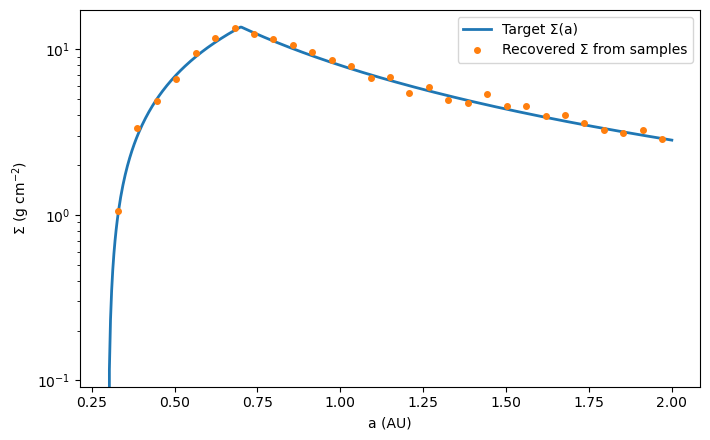

In [59]:
# -------------------------------------------------------------
# Example: Chambers-like setup
# -------------------------------------------------------------
# total mass and counts
Mtot_sol = 2.604 * (u.M_earth.to(u.solMass))  # total solids in solar masses
N = 2**13
m_pl_sol = Mtot_sol / N
m_pl_g = m_pl_sol * u.solMass.to(u.g)

# sample semi-major axes from disk
rng = np.random.default_rng(42)
a_samples = sample_a_from_disk(size=N, rng=rng)

# other orbital elements
inc = rng.uniform(0.0, 0.0175, N)          # rad
ecc = rng.uniform(0.0, 0.01, N)
Omega = rng.uniform(0.0, 2*np.pi, N)       # longitude of ascending node
omega = rng.uniform(0.0, 2*np.pi, N)       # argument of periapsis
Mmean = rng.uniform(0.0, 2*np.pi, N)       # mean anomaly

# build output array: < m a e inc O w M >
out = np.column_stack([
    np.full(N, m_pl_sol, dtype=float),
    a_samples,
    ecc,
    inc,
    Omega,
    omega,
    Mmean,
])

fname = f"initial_chambers_{N:.1e}_pls.dat"
np.savetxt(fname, out, fmt="%.10e")
print(f"Wrote {fname}")

# Diagnostics plot: recovered surface density vs target laws
centers, sigma_est = compute_surface_density(a_samples, m_pl_g, bins=np.linspace(0.3, 2.0, 30))

a = np.linspace(0.3, 2.0, 500)
Sig = np.where(a < A_BREAK, sigma_inner(a), sigma_out(a))

plt.figure(figsize=(7.2, 4.5))
plt.plot(a, Sig, lw=2, label="Target Σ(a)")
plt.plot(centers, sigma_est, "o", ms=4, label="Recovered Σ from samples")
plt.yscale("log")
plt.xlabel("a (AU)")
plt.ylabel(r"Σ (g cm$^{-2}$)")
plt.legend()
plt.tight_layout()
plt.show()
# plt.savefig("surface_density_check.png", dpi=160)
# print("Saved surface_density_check.png")


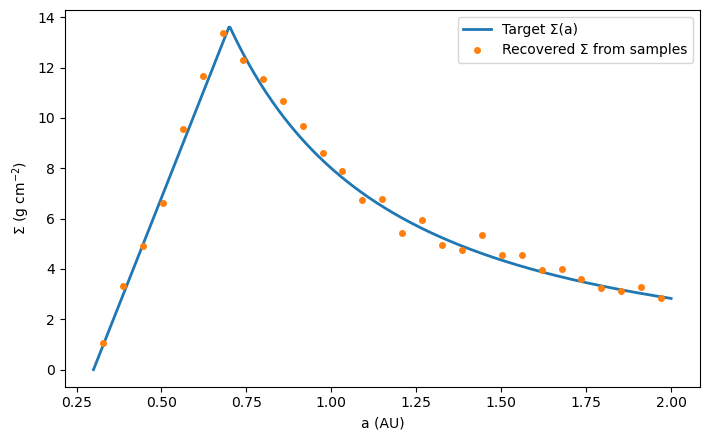

In [60]:
plt.figure(figsize=(7.2, 4.5))
plt.plot(a, Sig, lw=2, label="Target Σ(a)")
plt.plot(centers, sigma_est, "o", ms=4, label="Recovered Σ from samples")
plt.yscale("linear")
plt.xlabel("a (AU)")
plt.ylabel(r"Σ (g cm$^{-2}$)")
plt.legend()
plt.tight_layout()
plt.show()

In [61]:
for i in np.arange(len(Sig)):
    if (np.abs(a[i] - 1.0) < 0.005) or (np.abs(a[i] - 2.0) < 0.005):
        print(a[i], Sig[i])

0.9983967935871743 8.019277103258037
1.001803607214429 7.978405405944715
1.9965931863727455 2.835669486469919
2.0 2.8284271247461903


In [62]:
import numpy as np

K = 0.01720209895  # Gaussian gravitational constant

def validate_genga_ic(path, fmt="kepler", angle_units="radian", disk_edges=(0.3, 2.0)):
    """
    fmt: 'kepler' for << m a e inc O w M >>,
         'cart'   for << x y z m vx vy vz rho >>
    angle_units: 'radian' or 'degree'
    """
    issues = []
    try:
        arr = np.loadtxt(path)
    except Exception as e:
        return [f"Failed to read file: {e}"]

    if arr.ndim == 1:
        arr = arr[None, :]
    n, c = arr.shape

    if fmt == "kepler":
        expected = 7
        if c != expected:
            issues.append(f"Column count {c} ≠ expected {expected} for Keplerian.")
        else:
            m, a, e, inc, Om, w, M = (arr[:,i] for i in range(7))
            # units / bounds
            if np.any(m <= 0): issues.append("Found non-positive masses.")
            if np.any((a < disk_edges[0]) | (a > disk_edges[1])):
                issues.append(f"Semi-major axes outside [{disk_edges[0]}, {disk_edges[1]}] AU.")
            if np.any(e < 0) or np.any(e >= 1): issues.append("Eccentricities must be in [0,1).")
            # angles
            if angle_units == "radian":
                wraps = lambda x: (x % (2*np.pi))
                bad_O = np.any((Om < 0) | (Om >= 2*np.pi))
                bad_w = np.any((w  < 0) | (w  >= 2*np.pi))
                bad_M = np.any((M  < 0) | (M  >= 2*np.pi))
                if bad_O or bad_w or bad_M:
                    issues.append("Angles out of [0, 2π) while Angle units=radian.")
            elif angle_units == "degree":
                bad_O = np.any((Om < 0) | (Om >= 360))
                bad_w = np.any((w  < 0) | (w  >= 360))
                bad_M = np.any((M  < 0) | (M  >= 360))
                if bad_O or bad_w or bad_M:
                    issues.append("Angles out of [0, 360) while Angle units=degree.")
            else:
                issues.append(f"Unknown angle_units={angle_units}")

    elif fmt == "cart":
        expected = 8
        if c != expected:
            issues.append(f"Column count {c} ≠ expected {expected} for Cartesian.")
        else:
            x, y, z, m, vx, vy, vz, rho = (arr[:,i] for i in range(8))
            if np.any(m <= 0): issues.append("Found non-positive masses.")
            # distance sanity
            r = np.sqrt(x*x + y*y + z*z)
            if np.any(r < disk_edges[0]) or np.any(r > disk_edges[1]*1.5):
                issues.append("Some radii far outside expected disk; check AU units.")
            # velocity sanity (scale check): warn if values look like AU/day (missing 0.0172 factor)
            vmag = np.sqrt(vx*vx + vy*vy + vz*vz)
            if np.nanmedian(vmag) > 1.0:  # heuristic
                issues.append("Velocities look large for AU/day′. Did you convert from AU/day by ×0.01720209895?")
    else:
        issues.append(f"Unknown fmt={fmt}")

    # general file hygiene
    if n == 0:
        issues.append("File has zero bodies.")
    if np.any(~np.isfinite(arr)):
        issues.append("NaN/Inf detected in file.")

    return issues

# Example usage:
# problems = validate_genga_ic("my_ic.txt", fmt="kepler", angle_units="radian")
# if problems: print("Problems:\n - " + "\n - ".join(problems))
# else: print("Looks OK for GENGA.")


In [63]:
problems = validate_genga_ic("/Users/wang.12220/Downloads/initial_chambers_1.0e+05_pls.dat", fmt="kepler", angle_units="radian")

In [64]:
if problems: 
    print("Problems:\n - " + "\n - ".join(problems))
else:
    print("Looks OK for GENGA.")

Looks OK for GENGA.
